# Cu-64 nel nucleo: microdosimetria → MKM → LQ → S(N) e RBE(N)

Metti questo notebook nella **radice del progetto** (dove c'è la cartella `runs/`) ed esegui le celle in ordine.
Il passo lento è uno solo (la cella *"Campionamento delle dosi"*): il risultato viene salvato in `cache_dosi.npz`,
quindi puoi cambiare pesi, `alpha_0`, `beta`, `G` e rifare grafici e tabelle in pochi secondi.

## 0. Parametri

In [22]:
import glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILES = sorted(glob.glob("runs/run_*/yz.root"))
TREE = "yz"

# --- modello ---
R_d, R_n = 0.420, 4.0        # um   raggio dominio (= /microyz/det/Radius) e raggio nucleo
y0 = 150.0                   # keV/um  saturazione MKM
alpha_0, beta = 0.147, 0.02  # Gy^-1, Gy^-2 (raggi X)
G = 1.0                      # Lea-Catcheside: 1 = dose istantanea, <1 se protratta.
                             # L'RBE e' sempre rispetto a raggi X con lo stesso G (isola l'effetto della qualita' della radiazione)
rho = 1e-15                  # kg/um^3
KEV_J, EV_J = 1.602176634e-16, 1.602176634e-19
S_TARGET = 0.10
K_CONV = KEV_J / (rho * np.pi * R_d**2)     # Gy per keV/um

# --- statistica ---
N_SIM = 400                  # cellule virtuali per pool
N_POINTS = 60                # punti sull'asse N
N_BOOT = 20                  # pool bootstrap (solo se hai UN file)
SEED = 12345
WEIGHT_MODES = ("1/n", "N/n")   # 1/n: correzione dentro l'evento; N/n: anche tra eventi
PLOT_MODE = "N/n"

print(f"{len(FILES)} file trovati;  K_CONV = {K_CONV:.4f} Gy per keV/um")

10 file trovati;  K_CONV = 0.2891 Gy per keV/um


## 1. Lettura dei file

In [23]:
import uproot

cols = ["y", "nbHits", "nbScoredHits", "Nuclear_dose"]
dfs = [uproot.open(f)[TREE].arrays(cols, library="pd") for f in FILES]
print("eventi per file:", [len(d) for d in dfs])
dfs[0].head()

eventi per file: [20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000]


,y,nbHits,nbScoredHits,Nuclear_dose
0,0.635013,97.0,36.0,0.000543
1,8.708819,906.0,535.0,0.004976
2,8.622327,925.0,530.0,0.004977
3,4.951458,353.0,300.0,0.001974
4,0.307328,26.0,22.0,0.000124


## 2. Controlli
- **Allineamento:** l'energia nel nucleo (da `Nuclear_dose`) deve essere ≥ quella nel dominio (da `y`). Frazione attesa: 1.0000.
- **Seed:** i run devono avere eventi diversi.

In [24]:
def check_alignment(df, label=""):
    m_nucl = 1e3 * 4/3 * np.pi * (R_n * 1e-6) ** 3
    e_nucl = df["Nuclear_dose"].to_numpy() * m_nucl / EV_J     # eV nel nucleo
    eps = df["y"].to_numpy() * (4 * R_d / 3 * 1000.0)          # eV nel dominio
    ok = np.mean(e_nucl >= eps * (1 - 1e-3) - 0.5)
    print(f"[check] {label}: righe coerenti = {ok:.4f}")
    return ok

check_ok = [check_alignment(d, f) for f, d in zip(FILES, dfs)]

seed_msg = "un solo file (non verificabile)"
if len(dfs) > 1:
    heads = [d["y"].to_numpy()[:200].tobytes() for d in dfs]
    seed_msg = "run tutti diversi" if len(set(heads)) == len(heads) else "ATTENZIONE: run identici, seed non cambiati!"
print("[seed]", seed_msg)

[check] runs/run_01/yz.root: righe coerenti = 1.0000
[check] runs/run_02/yz.root: righe coerenti = 1.0000
[check] runs/run_03/yz.root: righe coerenti = 1.0000
[check] runs/run_04/yz.root: righe coerenti = 1.0000
[check] runs/run_05/yz.root: righe coerenti = 1.0000
[check] runs/run_06/yz.root: righe coerenti = 1.0000
[check] runs/run_07/yz.root: righe coerenti = 1.0000
[check] runs/run_08/yz.root: righe coerenti = 1.0000
[check] runs/run_09/yz.root: righe coerenti = 1.0000
[check] runs/run_10/yz.root: righe coerenti = 1.0000
[seed] run tutti diversi


## 3. Pool (un pool = una simulazione indipendente)

In [25]:
def make_pools(dfs, rng):
    if len(dfs) > 1:
        return dfs
    df = dfs[0]
    print(f"un solo file: uso {N_BOOT} pool bootstrap")
    return [df.iloc[rng.integers(0, len(df), len(df))].reset_index(drop=True) for _ in range(N_BOOT)]

rng = np.random.default_rng(SEED)
pools = make_pools(dfs, rng)
print(len(pools), "pool")

10 pool


## 4. Microdosimetria: y_F, y_D, y*
Per ogni pool e per ciascuno schema di peso. Gli errori (`sem`) sono tra pool.

In [26]:
def weights(df, mode):
    n = df["nbScoredHits"].to_numpy(float)
    big_n = df["nbHits"].to_numpy(float)
    return 1.0 / n if mode == "1/n" else big_n / n

def micro(df, mode):
    y = df["y"].to_numpy()
    w = weights(df, mode)
    y_f = np.sum(w * y) / np.sum(w)
    y_d = np.sum(w * y**2) / np.sum(w * y)
    y_star = np.sum(w * y0**2 * (1.0 - np.exp(-(y / y0) ** 2))) / np.sum(w * y)
    return y_f, y_d, y_star

rows = []
for i, p in enumerate(pools):
    for mode in WEIGHT_MODES:
        yf, yd, ys = micro(p, mode)
        rows.append(dict(pool=i, peso=mode, yF=yf, yD=yd, ystar=ys,
                         alpha=alpha_0 + beta * K_CONV * ys))
tab_micro = pd.DataFrame(rows)
tab_micro.groupby("peso")[["yF", "yD", "ystar", "alpha"]].agg(["mean", "sem"])

yF                  yD               ystar               alpha  \
          mean       sem      mean       sem      mean       sem      mean   
peso                                                                         
1/n   0.187951  0.000595  1.888969  0.007032  1.887031  0.007018  0.157911   
N/n   1.127767  0.005320  4.804801  0.010795  4.798184  0.010761  0.174744   

                
           sem  
peso            
1/n   0.000041  
N/n   0.000062

## 5. Spettri pesati f(y) e d(y) (tutti i run insieme)

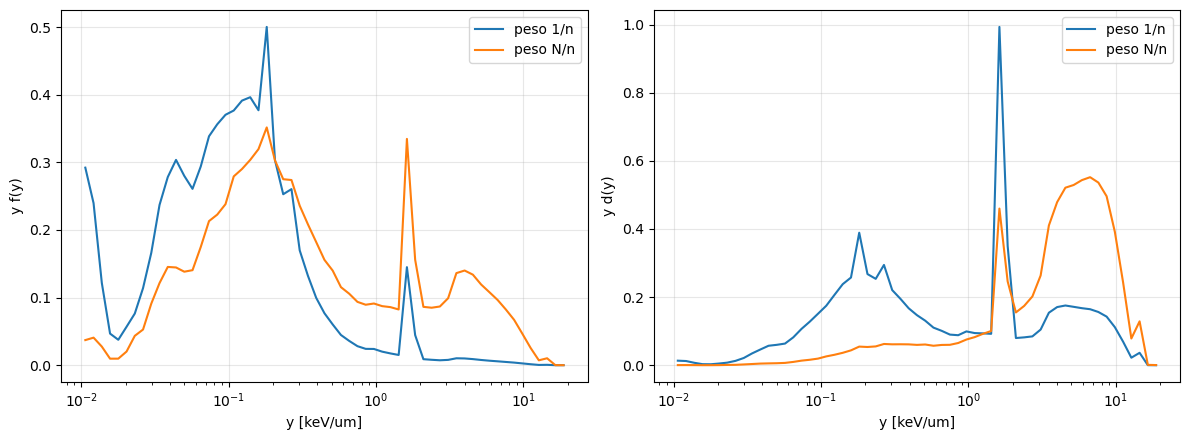

In [27]:
allp = pd.concat(pools, ignore_index=True)
bins = np.logspace(-2, np.log10(20), 60)
x = np.sqrt(bins[:-1] * bins[1:])
dln = np.diff(np.log(bins))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for mode in WEIGHT_MODES:
    w = weights(allp, mode)
    y = allp["y"].to_numpy()
    f = np.histogram(y, bins=bins, weights=w)[0];     f = f / f.sum() / dln
    d = np.histogram(y, bins=bins, weights=w * y)[0]; d = d / d.sum() / dln
    ax[0].semilogx(x, f, label=f"peso {mode}")
    ax[1].semilogx(x, d, label=f"peso {mode}")
ax[0].set_ylabel("y f(y)"); ax[1].set_ylabel("y d(y)")
for a in ax:
    a.set_xlabel("y [keV/um]"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

## 5b. Esplorazione dei dati grezzi: istogrammi 1D e 2D (tutti i run)
Qui si leggono **tutte** le colonne dei `.root` (non solo le quattro usate dal modello) e si aggiungono alcune grandezze derivate
(energie in keV, rapporto `nbScoredHits/nbHits`, i due pesi). I grafici sono pensati per trarre conclusioni:
- **1D:** ogni variabile, con ogni run in blu e la media dei run in nero (se i run coincidono, la statistica è stabile).
- **2D a matrice:** tutte le coppie di variabili, con la correlazione di Spearman nel triangolo alto.
- **2D mirati:** le coppie con un significato fisico, con le rette di riferimento (limiti, proporzionalità).

In [28]:
import uproot
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D

CYTO_THICK = 1.0     # um  (= /microyz/det/setCytoThickness)

def read_all(f):
    return uproot.open(f)[TREE].arrays(library="pd")          # TUTTE le colonne del tree

full = pd.concat([read_all(f).assign(run=i + 1) for i, f in enumerate(FILES)], ignore_index=True)

# --- grandezze derivate ---
m_nucl = 1e3 * 4/3 * np.pi * (R_n * 1e-6) ** 3                                        # kg
m_cyto = 1e3 * 4/3 * np.pi * (((R_n + CYTO_THICK) * 1e-6) ** 3 - (R_n * 1e-6) ** 3)   # kg
full["E_nucl_keV"]  = full["Nuclear_dose"] * m_nucl / KEV_J        # energia depositata nel nucleo
full["E_cyto_keV"]  = full["Cytoplasmic_dose"] * m_cyto / KEV_J    # energia depositata nel citoplasma
full["eps_dom_keV"] = full["y"] * (4 * R_d / 3)                    # energia nel dominio (y * l_medio)
full["ratio"]       = full["nbScoredHits"] / full["nbHits"]
full["w_1n"]        = 1.0 / full["nbScoredHits"]
full["w_Nn"]        = full["nbHits"] / full["nbScoredHits"]

num = full.drop(columns="run")
stat = pd.DataFrame({"media": num.mean(), "mediana": num.median(), "std": num.std(),
                     "min": num.min(), "max": num.max(), "frazione = 0": (num == 0).mean()})
const = [c for c in num.columns if num[c].nunique() == 1]

print(f"{len(full)} eventi totali in {len(FILES)} file")
print("colonne costanti (non plottate):", {c: float(num[c].iloc[0]) for c in const})
stat.drop(index=const).round(5)

200000 eventi totali in 10 file
colonne costanti (non plottate): {'eventID': 0.0, 'radius': 420.0, 'Einc': 0.0}


,media,mediana,std,min,max,frazione = 0
nbHits,279.84144,101.00000,358.31993,1.00000,4286.00000,0.00000
nbScoredHits,125.30326,59.00000,169.20989,1.00000,1143.00000,0.00000
y,2.04122,0.96191,2.74588,0.00003,18.56029,0.00000
z,0.59014,0.27810,0.79386,0.00001,5.36595,0.00000
Nuclear_dose,0.00154,0.00054,0.00194,0.00000,0.02363,0.00000
Cytoplasmic_dose,0.00030,0.00007,0.00079,0.00000,0.01415,0.40414
r_domain_center,3.11182,3.29408,0.78296,0.08123,4.41854,0.00000
E_nucl_keV,2.57874,0.90789,3.24986,0.00002,39.53404,0.00000
E_cyto_keV,0.48547,0.11606,1.25589,0.00000,22.56737,0.40414
eps_dom_keV,1.14308,0.53867,1.53769,0.00002,10.39376,0.00000


### 1D: ogni variabile
Linee blu = singoli run (conteggi per run), linea nera = media dei run. Asse y sempre logaritmico.

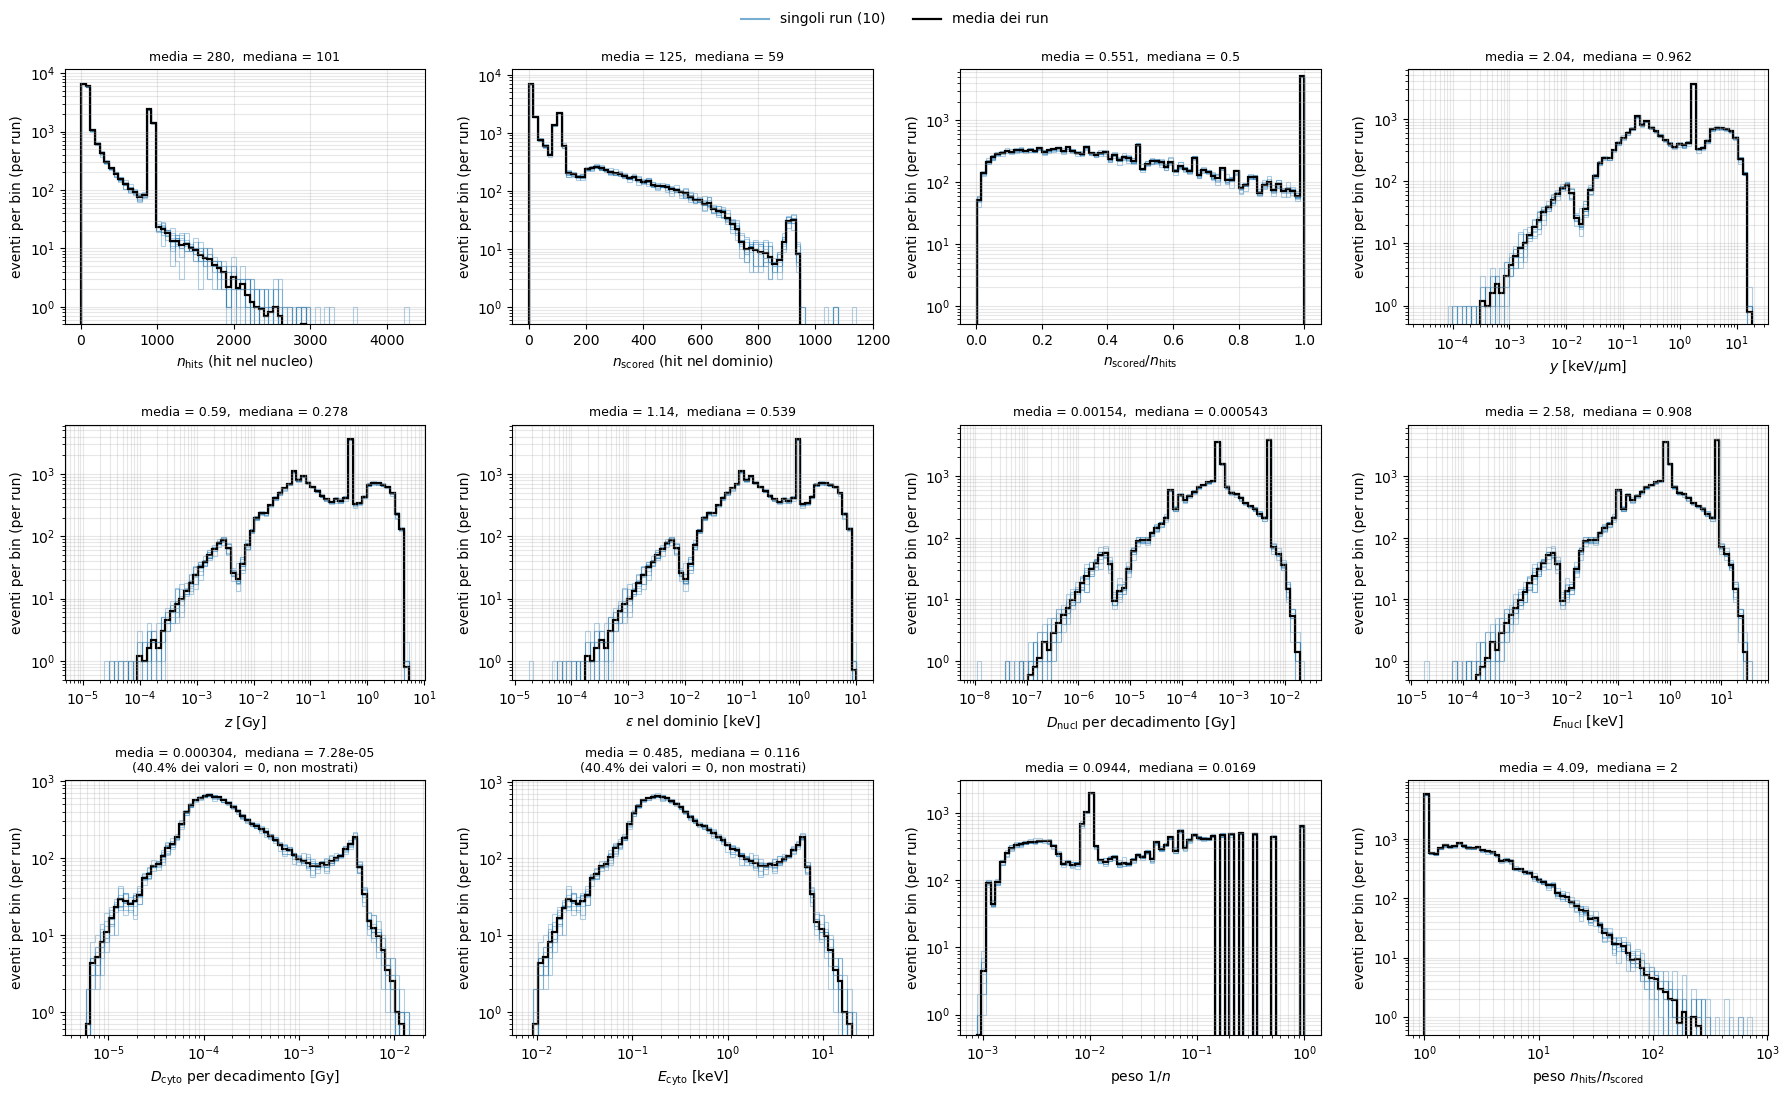

In [29]:
runs = sorted(full["run"].unique())

PANELS = [   # (colonna, etichetta asse x, scala x)
    ("nbHits",           r"$n_{\rm hits}$ (hit nel nucleo)",          "lin"),
    ("nbScoredHits",     r"$n_{\rm scored}$ (hit nel dominio)",       "lin"),
    ("ratio",            r"$n_{\rm scored}/n_{\rm hits}$",           "lin"),
    ("y",                r"$y$ [keV/$\mu$m]",                         "log"),
    ("z",                r"$z$ [Gy]",                                  "log"),
    ("eps_dom_keV",      r"$\varepsilon$ nel dominio [keV]",          "log"),
    ("Nuclear_dose",     r"$D_{\rm nucl}$ per decadimento [Gy]",      "log"),
    ("E_nucl_keV",       r"$E_{\rm nucl}$ [keV]",                     "log"),
    ("Cytoplasmic_dose", r"$D_{\rm cyto}$ per decadimento [Gy]",      "log"),
    ("E_cyto_keV",       r"$E_{\rm cyto}$ [keV]",                     "log"),
    ("w_1n",             r"peso $1/n$",                                "log"),
    ("w_Nn",             r"peso $n_{\rm hits}/n_{\rm scored}$",      "log"),
]

def make_bins(x, scale, nb=70):
    x = x[np.isfinite(x)]
    if scale == "log":
        x = x[x > 0]
        return np.logspace(np.log10(x.min()), np.log10(x.max()), nb + 1)
    return np.linspace(x.min(), x.max(), nb + 1)

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, (col, lab, scale) in zip(axes.ravel(), PANELS):
    x_all = full[col].to_numpy()
    bins = make_bins(x_all, scale)
    H = np.array([np.histogram(full.loc[full["run"] == r, col], bins=bins)[0] for r in runs])
    for h in H:
        ax.stairs(h, bins, color="tab:blue", alpha=0.35, lw=0.8)
    ax.stairs(H.mean(axis=0), bins, color="k", lw=1.6)
    ax.set_yscale("log")
    ax.set_ylim(bottom=0.5)
    if scale == "log":
        ax.set_xscale("log")
    ax.set_xlabel(lab)
    ax.set_ylabel("eventi per bin (per run)")
    z0 = np.mean(x_all == 0)
    ax.set_title(f"media = {x_all.mean():.3g},  mediana = {np.median(x_all):.3g}"
                 + (f"\n({100 * z0:.1f}% dei valori = 0, non mostrati)" if z0 > 0 else ""), fontsize=9)
    ax.grid(alpha=0.3, which="both")

fig.legend(handles=[Line2D([], [], color="tab:blue", alpha=0.6, label=f"singoli run ({len(runs)})"),
                    Line2D([], [], color="k", lw=1.6, label="media dei run")],
           loc="upper center", ncol=2, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig("hist1d_tutte_le_variabili.png", dpi=150, bbox_inches="tight")
plt.show()

### 2D: tutte le coppie (matrice)
Triangolo basso: istogrammi 2D (scala di colore logaritmica, tutti gli eventi di tutti i run). Diagonale: istogramma 1D.
Triangolo alto: correlazione di Spearman (misura la monotonia, quindi regge bene anche con distribuzioni a code lunghe).
Tutte le variabili sono in `log10`; i valori **uguali a 0** (ad es. la dose citoplasmatica) sono messi nel bin più a sinistra, e il nome
dell'asse ha un asterisco.

* Cytoplasmic_dose: 40.4% dei valori sono 0 (nel bin piu' a sinistra)


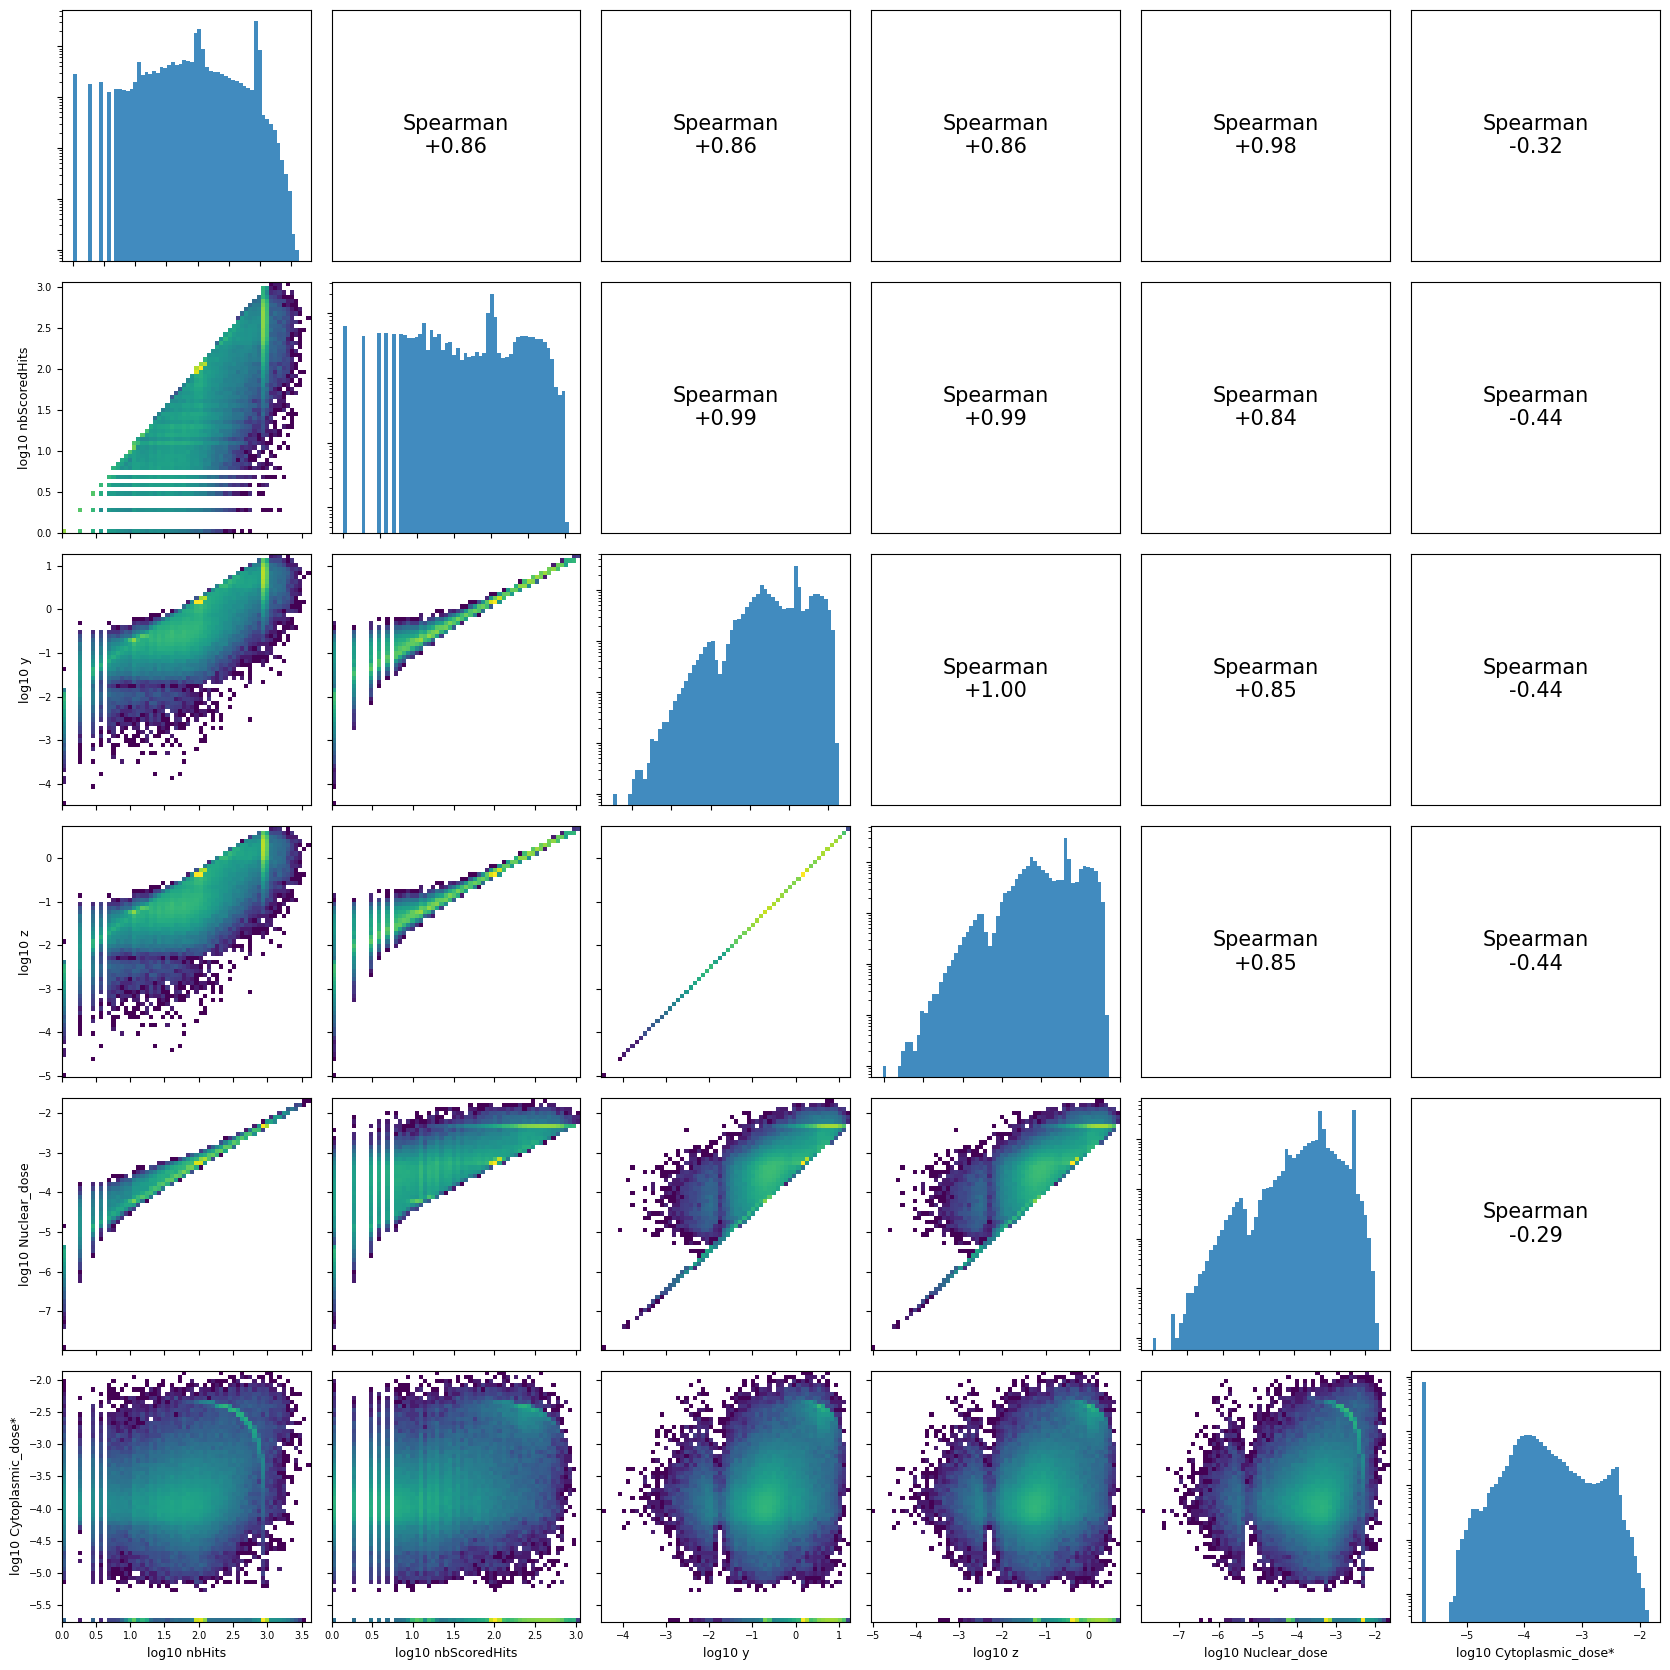

In [30]:
PAIR_VARS = ["nbHits", "nbScoredHits", "y", "z", "Nuclear_dose", "Cytoplasmic_dose"]   # modificabile

def to_log(x):
    """log10 con gli zeri messi sotto il minimo positivo (floor = min/3). Restituisce anche la frazione di zeri."""
    x = np.asarray(x, float)
    pos = x > 0
    floor = x[pos].min() / 3.0
    return np.log10(np.where(pos, x, floor)), float((~pos).mean())

L, zfrac = {}, {}
for c in PAIR_VARS:
    L[c], zfrac[c] = to_log(full[c].to_numpy())
rho_s = full[PAIR_VARS].corr(method="spearman")

n = len(PAIR_VARS)
fig, axes = plt.subplots(n, n, figsize=(2.8 * n, 2.8 * n))
for i, ci in enumerate(PAIR_VARS):            # riga  -> asse y
    for j, cj in enumerate(PAIR_VARS):        # colonna -> asse x
        ax = axes[i, j]
        if i == j:
            ax.hist(L[ci], bins=60, color="tab:blue", alpha=0.85)
            ax.set_yscale("log")
        elif i > j:
            ax.hist2d(L[cj], L[ci], bins=60, norm=LogNorm(), cmin=1, cmap="viridis")
        else:
            ax.text(0.5, 0.5, f"Spearman\n{rho_s.loc[ci, cj]:+.2f}", ha="center", va="center",
                    fontsize=15, transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
        ax.tick_params(labelsize=7, labelbottom=(i == n - 1), labelleft=(j == 0 and i > 0))
        if i == n - 1:
            ax.set_xlabel("log10 " + cj + ("*" if zfrac[cj] > 0 else ""), fontsize=9)
        if j == 0 and i > 0:
            ax.set_ylabel("log10 " + ci + ("*" if zfrac[ci] > 0 else ""), fontsize=9)

for c in PAIR_VARS:
    if zfrac[c] > 0:
        print(f"* {c}: {100 * zfrac[c]:.1f}% dei valori sono 0 (nel bin piu' a sinistra)")
plt.tight_layout()
fig.savefig("hist2d_matrice.png", dpi=150, bbox_inches="tight")
plt.show()

### 2D mirati, con le rette di riferimento
Ognuno di questi grafici ha un significato fisico preciso:
- `n_scored` vs `n_hits`: la sfera non può contenere più hit del nucleo (retta `n = N`).
- `E_nucl` vs `ε_dominio`: l'energia nel nucleo non può essere minore di quella nel dominio (retta `E = ε`; la frazione sotto la retta deve essere 0).
- `E_nucl` vs `n_hits`: l'energia è circa proporzionale al numero di hit (energia media per hit).
- `E_cyto` vs `E_nucl`: gli eventi che depositano energia fuori dal nucleo.
- `z` vs `y`: proporzionalità esatta `z = K_CONV · y`.
- `y` vs `n_scored` / `n_hits`, e i due pesi vs `y`: servono per discutere i pesi.

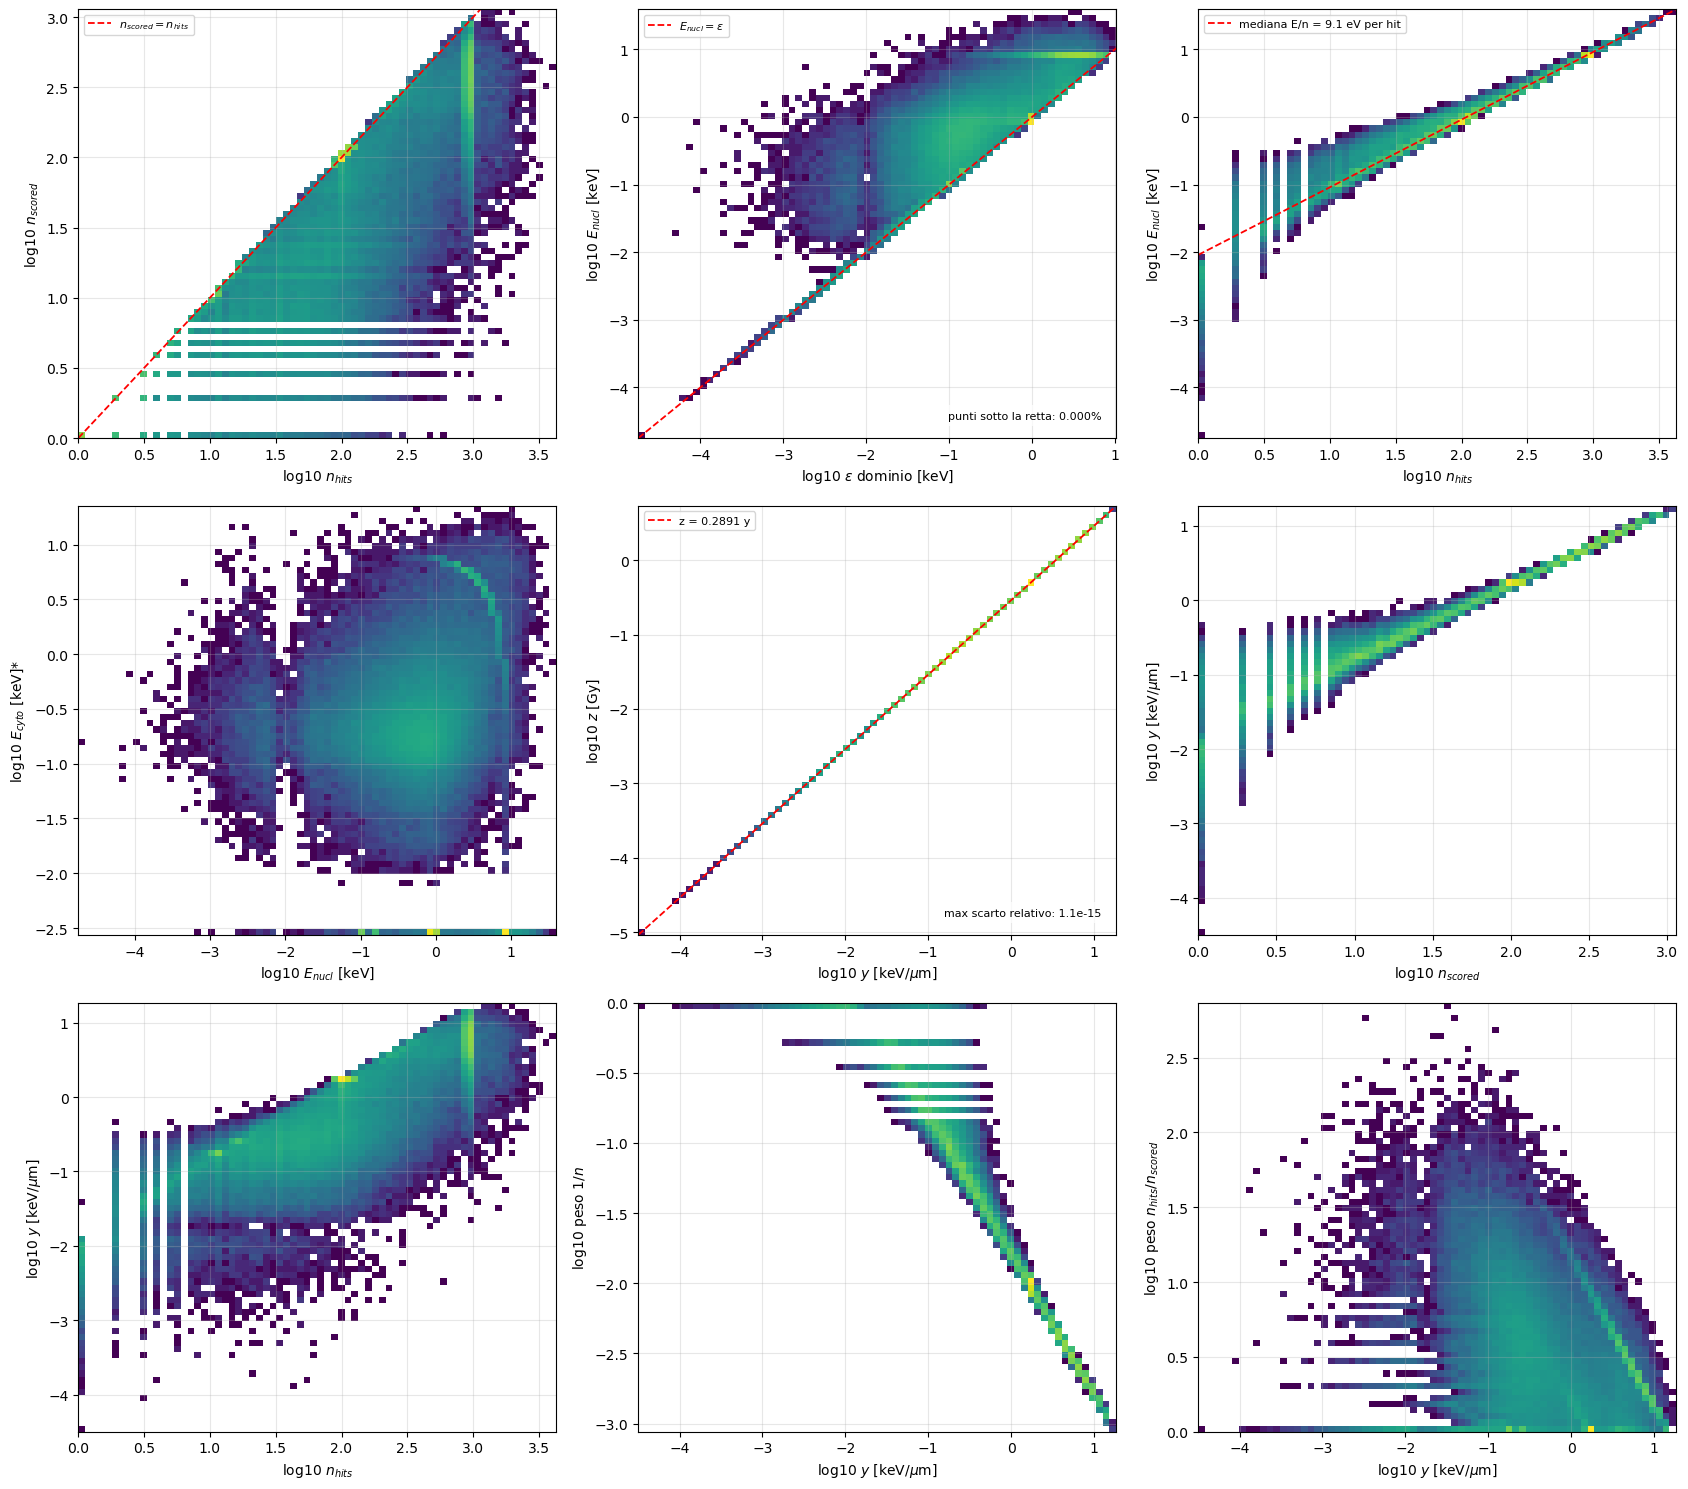

In [31]:
def panel(ax, xcol, ycol, xlab, ylab, ref=None, ref_label=None, note=None, nb=70):
    xl, xz = to_log(full[xcol].to_numpy())
    yl, yz = to_log(full[ycol].to_numpy())
    ax.hist2d(xl, yl, bins=nb, norm=LogNorm(), cmin=1, cmap="viridis")
    ax.set_xlabel("log10 " + xlab + ("*" if xz > 0 else ""))
    ax.set_ylabel("log10 " + ylab + ("*" if yz > 0 else ""))
    if ref is not None:
        xs = np.array(ax.get_xlim())
        ax.plot(xs, ref(xs), "r--", lw=1.3, label=ref_label)
        ax.set_xlim(*xs)
        ax.legend(loc="upper left", fontsize=8)
    if note:
        ax.text(0.97, 0.04, note, transform=ax.transAxes, ha="right", va="bottom", fontsize=8,
                bbox=dict(fc="white", alpha=0.75, lw=0))
    ax.grid(alpha=0.3)

viol = np.mean(full["E_nucl_keV"] < full["eps_dom_keV"] * (1 - 1e-3) - 5e-4)
dev_z = np.max(np.abs(full["z"] / (K_CONV * full["y"]) - 1))
k_eh = np.median(full["E_nucl_keV"] / full["nbHits"])            # keV per hit

fig, axes = plt.subplots(3, 3, figsize=(17, 15))
panel(axes[0, 0], "nbHits", "nbScoredHits", r"$n_{hits}$", r"$n_{scored}$",
      ref=lambda x: x, ref_label=r"$n_{scored} = n_{hits}$")
panel(axes[0, 1], "eps_dom_keV", "E_nucl_keV", r"$\varepsilon$ dominio [keV]", r"$E_{nucl}$ [keV]",
      ref=lambda x: x, ref_label=r"$E_{nucl} = \varepsilon$", note=f"punti sotto la retta: {100 * viol:.3f}%")
panel(axes[0, 2], "nbHits", "E_nucl_keV", r"$n_{hits}$", r"$E_{nucl}$ [keV]",
      ref=lambda x: x + np.log10(k_eh), ref_label=f"mediana E/n = {k_eh * 1e3:.1f} eV per hit")
panel(axes[1, 0], "E_nucl_keV", "E_cyto_keV", r"$E_{nucl}$ [keV]", r"$E_{cyto}$ [keV]")
panel(axes[1, 1], "y", "z", r"$y$ [keV/$\mu$m]", r"$z$ [Gy]",
      ref=lambda x: x + np.log10(K_CONV), ref_label=f"z = {K_CONV:.4f} y",
      note=f"max scarto relativo: {dev_z:.1e}")
panel(axes[1, 2], "nbScoredHits", "y", r"$n_{scored}$", r"$y$ [keV/$\mu$m]")
panel(axes[2, 0], "nbHits", "y", r"$n_{hits}$", r"$y$ [keV/$\mu$m]")
panel(axes[2, 1], "y", "w_1n", r"$y$ [keV/$\mu$m]", r"peso $1/n$")
panel(axes[2, 2], "y", "w_Nn", r"$y$ [keV/$\mu$m]", r"peso $n_{hits}/n_{scored}$")

plt.tight_layout()
fig.savefig("hist2d_mirati.png", dpi=150, bbox_inches="tight")
plt.show()

### Correlazioni (tabella e mappa)
Correlazione di Spearman tra tutte le variabili numeriche interessanti. Utile per vedere subito cosa dipende da cosa.

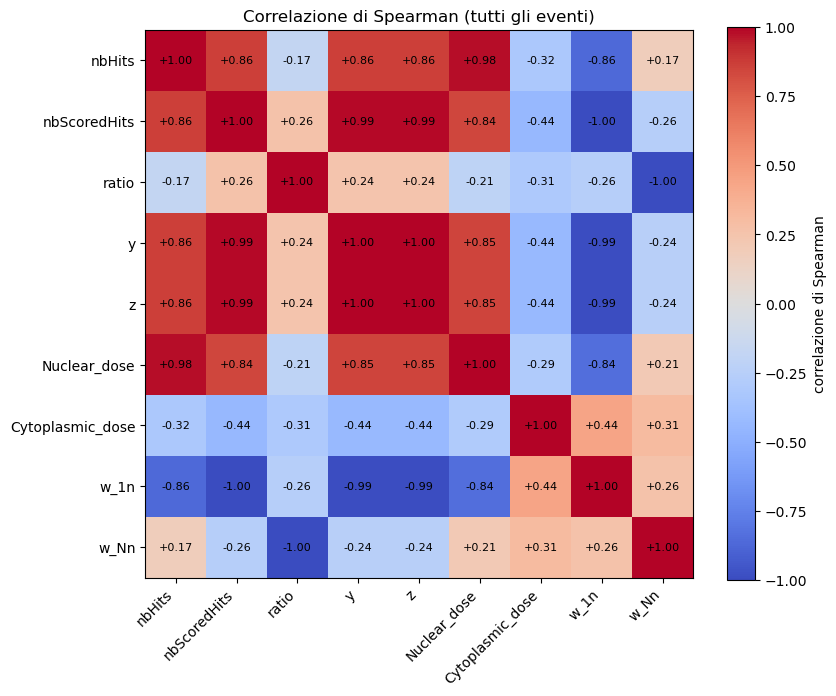

,nbHits,nbScoredHits,ratio,y,z,Nuclear_dose,Cytoplasmic_dose,w_1n,w_Nn
nbHits,1.000,0.864,-0.173,0.860,0.860,0.982,-0.315,-0.864,0.173
nbScoredHits,0.864,1.000,0.258,0.991,0.991,0.840,-0.441,-1.000,-0.258
ratio,-0.173,0.258,1.000,0.245,0.245,-0.207,-0.307,-0.258,-1.000
y,0.860,0.991,0.245,1.000,1.000,0.848,-0.436,-0.991,-0.245
z,0.860,0.991,0.245,1.000,1.000,0.848,-0.436,-0.991,-0.245
Nuclear_dose,0.982,0.840,-0.207,0.848,0.848,1.000,-0.294,-0.840,0.207
Cytoplasmic_dose,-0.315,-0.441,-0.307,-0.436,-0.436,-0.294,1.000,0.441,0.307
w_1n,-0.864,-1.000,-0.258,-0.991,-0.991,-0.840,0.441,1.000,0.258
w_Nn,0.173,-0.258,-1.000,-0.245,-0.245,0.207,0.307,0.258,1.000


In [32]:
CORR_VARS = ["nbHits", "nbScoredHits", "ratio", "y", "z", "Nuclear_dose", "Cytoplasmic_dose", "w_1n", "w_Nn"]
rho_all = full[CORR_VARS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(rho_all.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR_VARS))); ax.set_xticklabels(CORR_VARS, rotation=45, ha="right")
ax.set_yticks(range(len(CORR_VARS))); ax.set_yticklabels(CORR_VARS)
for i in range(len(CORR_VARS)):
    for j in range(len(CORR_VARS)):
        ax.text(j, i, f"{rho_all.values[i, j]:+.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="correlazione di Spearman")
ax.set_title("Correlazione di Spearman (tutti gli eventi)")
plt.tight_layout()
fig.savefig("correlazioni.png", dpi=150, bbox_inches="tight")
plt.show()
rho_all.round(3)

## 5c. Range dei positroni (β⁺) dagli istogrammi dei `.root`
`SteppingAction` riempie tre istogrammi a ogni vera annichilazione di un positrone (processo `annihil`):
- `r_creation`: distanza dal centro del nucleo del punto di emissione;
- `r_annihilation`: distanza dal centro del punto di annichilazione;
- `displacement`: distanza tra emissione e annichilazione (il **range** in linea d'aria, non la lunghezza del percorso).

**Attenzione al binning.** Nei run vecchi `CreateH1(..., 400, 0., 2000., "um")` passava gli estremi in unità interne di Geant4 (mm), quindi l'asse arrivava a 2000 mm
con bin da 5 mm: tutti i positroni cadevano nel primo bin e il range non si misura. Nel `RunAction` va scritto, ad esempio, `3.*mm` o `5.*um` (vedi la chat).
Per questo la cella legge i file da `runs_beta/run_*/yz.root` (run con i nuovi istogrammi) e avvisa se trova bin troppo larghi.

Controlli utili: positroni per decadimento ≈ 0.175 (ramo β⁺ del Cu-64) e frazione in overflow (positroni oltre il limite dell'asse).

file usati: ['runs/run_01/yz.root', 'runs/run_02/yz.root', 'runs/run_03/yz.root', 'runs/run_04/yz.root', 'runs/run_05/yz.root', 'runs/run_06/yz.root', 'runs/run_07/yz.root', 'runs/run_08/yz.root', 'runs/run_09/yz.root', 'runs/run_10/yz.root']
oggetti nel primo file: ['yz;1', 'r_creation;1', 'r_annihilation;1', 'displacement;1']
larghezza bin = 5.0 um  (le quantita' sono note a +/- un bin)


,media,sem
positroni_per_decadimento,0.1754,0.0012
media_um,540.7110,2.4744
mediana_um,460.9667,3.5716
p95_um,1292.1729,6.7402
p99_um,1642.8867,8.8390
max_um,2175.5000,32.9937
frazione_overflow,0.0000,0.0000
frazione_nel_primo_bin,0.0015,0.0002


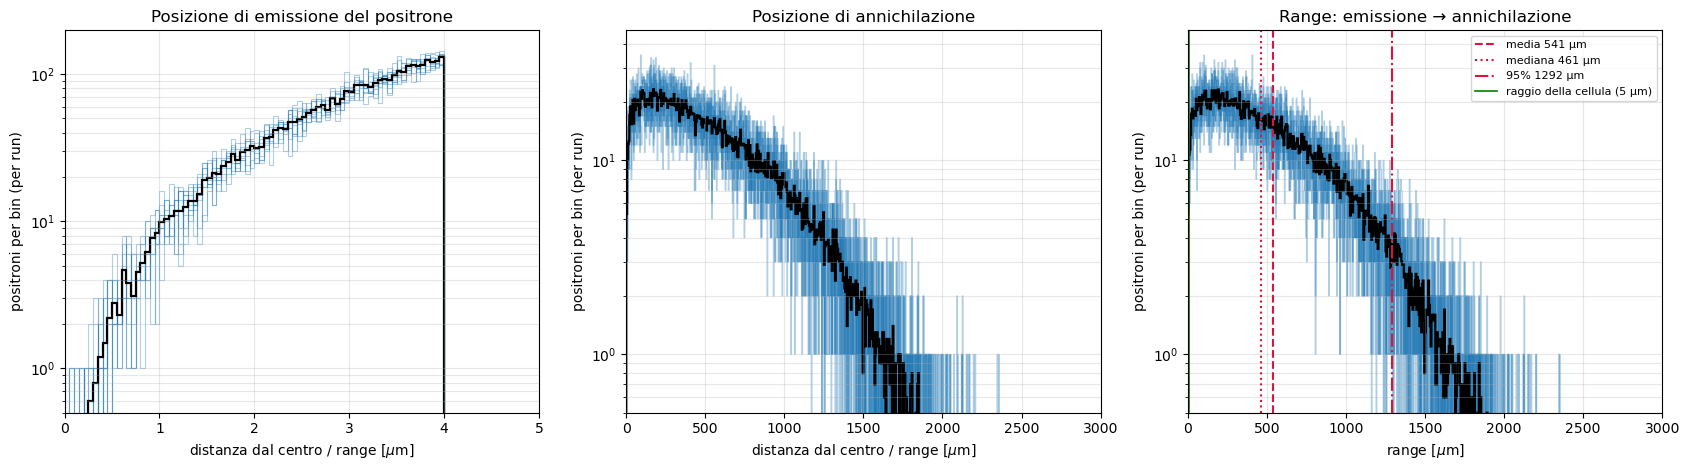

In [33]:
FILES_LIST = sorted(glob.glob("runs_beta/run_*/yz.root")) or FILES     # run con i nuovi istogrammi (cartella runs_beta/)
n_events = [uproot.open(f)[TREE].num_entries for f in FILES_LIST]       # decadimenti per run

print("file usati:", FILES_LIST)
print("oggetti nel primo file:", uproot.open(FILES_LIST[0]).keys())     # controllo: devono esserci i 3 istogrammi

def read_h1(f, name):
    h = uproot.open(f)[name]
    counts, edges = h.to_numpy()
    try:
        entries = float(h.member("fEntries"))    # tutti i riempimenti, compresi quelli fuori range
    except Exception:
        entries = np.nan
    return counts.astype(float), np.asarray(edges, float), entries

NAMES = ["r_creation", "r_annihilation", "displacement"]
H = {}
for name in NAMES:
    cs, es = [], []
    for f in FILES_LIST:
        c, edges, e = read_h1(f, name)
        cs.append(c); es.append(e)
    H[name] = dict(counts=np.array(cs), edges=edges, entries=np.array(es))
x = 0.5 * (H["displacement"]["edges"][:-1] + H["displacement"]["edges"][1:])     # um
bin_w = np.diff(H["displacement"]["edges"])[0]
if bin_w > 50:
    print(f"ATTENZIONE: bin larghi {bin_w:.0f} um (asse fino a {H['displacement']['edges'][-1]:.3g} um): "
          "istogrammi con il binning vecchio, il range NON e' misurabile. Rifai il run con RunAction corretto (vedi testo).")

# --- statistiche del range (distanza emissione -> annichilazione) per ogni run ---
rows = []
for k, (c, ent, nev) in enumerate(zip(H["displacement"]["counts"], H["displacement"]["entries"], n_events)):
    tot = c.sum()
    cum = np.cumsum(c) / tot
    up = H["displacement"]["edges"][1:]
    rows.append(dict(
        run=k + 1,
        positroni_per_decadimento=ent / nev,
        media_um=np.sum(c * x) / tot,
        mediana_um=np.interp(0.50, cum, up),
        p95_um=np.interp(0.95, cum, up),
        p99_um=np.interp(0.99, cum, up),
        max_um=up[np.nonzero(c)[0].max()],
        frazione_overflow=(ent - tot) / ent,
        frazione_nel_primo_bin=c[0] / tot))
tab_beta = pd.DataFrame(rows).set_index("run")
print(f"larghezza bin = {bin_w:.1f} um  (le quantita' sono note a +/- un bin)")
summary = pd.DataFrame({"media": tab_beta.mean(), "sem": tab_beta.sem()})
display(summary.round(4))

# --- grafici ---
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
titles = {"r_creation": "Posizione di emissione del positrone",
          "r_annihilation": "Posizione di annichilazione",
          "displacement": "Range: emissione → annichilazione"}
for a_, name in zip(ax, NAMES):
    ed = H[name]["edges"]; cc = H[name]["counts"]
    for c in cc:
        a_.stairs(c, ed, color="tab:blue", alpha=0.35, lw=0.8)
    a_.stairs(cc.mean(axis=0), ed, color="k", lw=1.6)
    a_.set_yscale("log"); a_.set_ylim(bottom=0.5)
    a_.set_xlabel(r"distanza dal centro / range [$\mu$m]" if name != "displacement" else r"range [$\mu$m]")
    a_.set_ylabel("positroni per bin (per run)")
    a_.set_xlim(0, min(ed[-1], 3500))
    a_.set_title(titles[name]); a_.grid(alpha=0.3, which="both")
m_, md_, p95_ = summary.loc[["media_um", "mediana_um", "p95_um"], "media"]
for v, ls, lab in ((m_, "--", f"media {m_:.0f} µm"), (md_, ":", f"mediana {md_:.0f} µm"), (p95_, "-.", f"95% {p95_:.0f} µm")):
    ax[2].axvline(v, color="crimson", ls=ls, label=lab)
ax[2].axvline(R_n + 1.0, color="green", ls="-", lw=1.2, label="raggio della cellula (5 µm)")
ax[2].legend(fontsize=8)
plt.tight_layout()
fig.savefig("range_beta_plus.png", dpi=150, bbox_inches="tight")
plt.show()

,media,sem
FWHM_um,225.7,5.0
FWTM_um,1159.5,11.7
sigma_1D_um,384.8,1.6
media_3D_um,540.7,2.5


tutti i run insieme: FWHM = 224 um, FWTM = 1161 um (35073 positroni)


,FWHM range [mm],FWHM totale [mm],range / totale,cellule per elemento (FWHM^3)
FWHM detector [mm],,,,
1.0,0.226,1.025,0.220,1.1e+06
2.0,0.226,2.013,0.112,8.2e+06
4.0,0.226,4.006,0.056,6.4e+07


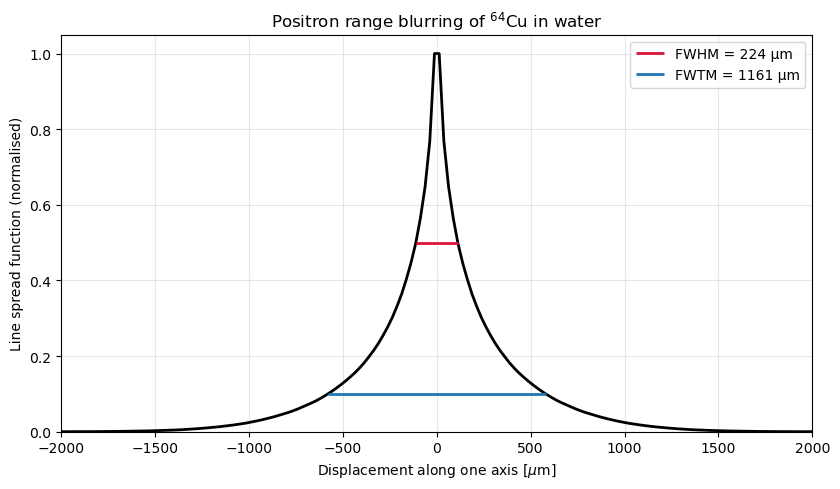

In [34]:
# ===== Sfocatura PET dal range del positrone: FWHM e FWTM della proiezione 1D (richiede la sezione 5c) =====
edges = H["displacement"]["edges"]                    # um
d = 0.5 * (edges[:-1] + edges[1:])                    # centri dei bin del range 3D
H_BIN = 25.0                                          # um, larghezza dei bin della proiezione

def lsf_1d(counts, h=H_BIN):
    """Densita' 1D della proiezione x = d*cos(theta), con direzione isotropa: P(|x|<=t | d) = min(1, t/d)."""
    p = counts / counts.sum()
    t = np.arange(0, edges[-1] + h, h)
    cdf = (p[None, :] * np.minimum(1.0, t[:, None] / d[None, :])).sum(axis=1)     # P(|x| <= t)
    f = np.diff(cdf) / h / 2.0                                                     # densita' per um
    return 0.5 * (t[:-1] + t[1:]), f

def width_at(xc, f, frac):
    """Larghezza completa al livello frac * massimo (FWHM: 0.5, FWTM: 0.1), con interpolazione lineare."""
    target = frac * f.max()
    i = int(np.argmax(f < target))
    x0, x1, f0, f1 = xc[i - 1], xc[i], f[i - 1], f[i]
    return 2.0 * (x0 + (f0 - target) / (f0 - f1) * (x1 - x0))

def stats_run(counts):
    xc, f = lsf_1d(counts)
    p = counts / counts.sum()
    return dict(FWHM_um=width_at(xc, f, 0.5), FWTM_um=width_at(xc, f, 0.1),
                sigma_1D_um=np.sqrt(np.sum(p * d**2) / 3.0), media_3D_um=np.sum(p * d))

cnt = H["displacement"]["counts"]                     # (run, bin)
tab_psf = pd.DataFrame([stats_run(c) for c in cnt])
tab_psf.index = np.arange(1, len(cnt) + 1); tab_psf.index.name = "run"
res = pd.DataFrame({"media": tab_psf.mean(), "sem": tab_psf.sem()})
display(res.round(1))
pooled = stats_run(cnt.sum(axis=0))
print(f"tutti i run insieme: FWHM = {pooled['FWHM_um']:.0f} um, FWTM = {pooled['FWTM_um']:.0f} um "
      f"({cnt.sum():.0f} positroni)")

# --- cosa significa per un'immagine PET (valori del detector ILLUSTRATIVI) ---
CELLS_PER_MM3 = 1e6                                    # cellule per mm^3 (illustrativo)
fwhm_r = res.loc["FWHM_um", "media"] / 1000.0          # mm
rows = []
for det in (1.0, 2.0, 4.0):                            # risoluzione intrinseca del detector, FWHM [mm]
    tot = np.hypot(det, fwhm_r)
    rows.append({"FWHM detector [mm]": det, "FWHM range [mm]": round(fwhm_r, 3), "FWHM totale [mm]": round(tot, 3),
                 "range / totale": round(fwhm_r / tot, 3), "cellule per elemento (FWHM^3)": f"{tot**3 * CELLS_PER_MM3:.1e}"})
display(pd.DataFrame(rows).set_index("FWHM detector [mm]"))

# --- grafico: LSF 1D del range ---
xc, f = lsf_1d(cnt.sum(axis=0))
xs = np.concatenate([-xc[::-1], xc]); fs = np.concatenate([f[::-1], f])
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(xs, fs / f.max(), color="k", lw=2)
for frac, col, lab, key in ((0.5, "crimson", "FWHM", "FWHM_um"), (0.1, "tab:blue", "FWTM", "FWTM_um")):
    w = pooled[key]
    ax.hlines(frac, -w / 2, w / 2, colors=col, lw=2, label=f"{lab} = {w:.0f} µm")
ax.set_xlim(-2000, 2000); ax.set_ylim(0, 1.05)
ax.set_xlabel(r"Displacement along one axis [$\mu$m]"); ax.set_ylabel("Line spread function (normalised)")
ax.set_title(r"Positron range blurring of $^{64}$Cu in water")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout()
fig.savefig("lsf_positron_range.png", dpi=200, bbox_inches="tight")
plt.show()

## 5d. Quanto pesano beta e Auger in f(y) e in y*? (per discutere i pesi)
Divide i decadimenti in due classi dall'energia depositata nel nucleo: **'Auger K'** (picco a 8.33 keV, l'energia di legame K del Ni) e **altri** (beta±, ecc.).
Poi confronta tre schemi di peso (`w = 1`, `1/n`, `N/n`) su: y_F, y_D, y*, α, la quota di ogni classe in Σw e in Σw·y,
e disegna `y f(y)` totale e diviso per classe.
Serve per capire *quanta* della bassa lineal energy viene dai beta e quanto sposta y*. Richiede la sezione 5b (`full`).

,y_F,y_D,y*,alpha,RBE(D->0),quota di Σw da 'Auger K',quota di Σw·y da 'Auger K'
peso,,,,,,,
w = 1 (un campione per decadimento),2.0412,5.7350,5.7250,0.1801,1.2252,0.1889,0.5824
w = 1/n,0.1879,1.8889,1.8870,0.1579,1.0742,0.0073,0.1731
w = N/n,1.1276,4.8050,4.7984,0.1747,1.1887,0.1539,0.6097


eventi 'Auger K' (E_nucl in [8.0, 8.6] keV): 18.9% dei decadimenti
  con y > 10 keV/um (cascata quasi tutta nel dominio): 11.5% di questi
  mediana di n_scored/n_hits: 0.40;  mediana di y: 5.89 keV/um
altri eventi (beta, ecc.): mediana di y = 0.419 keV/um;  mediana di n_scored/n_hits = 0.56


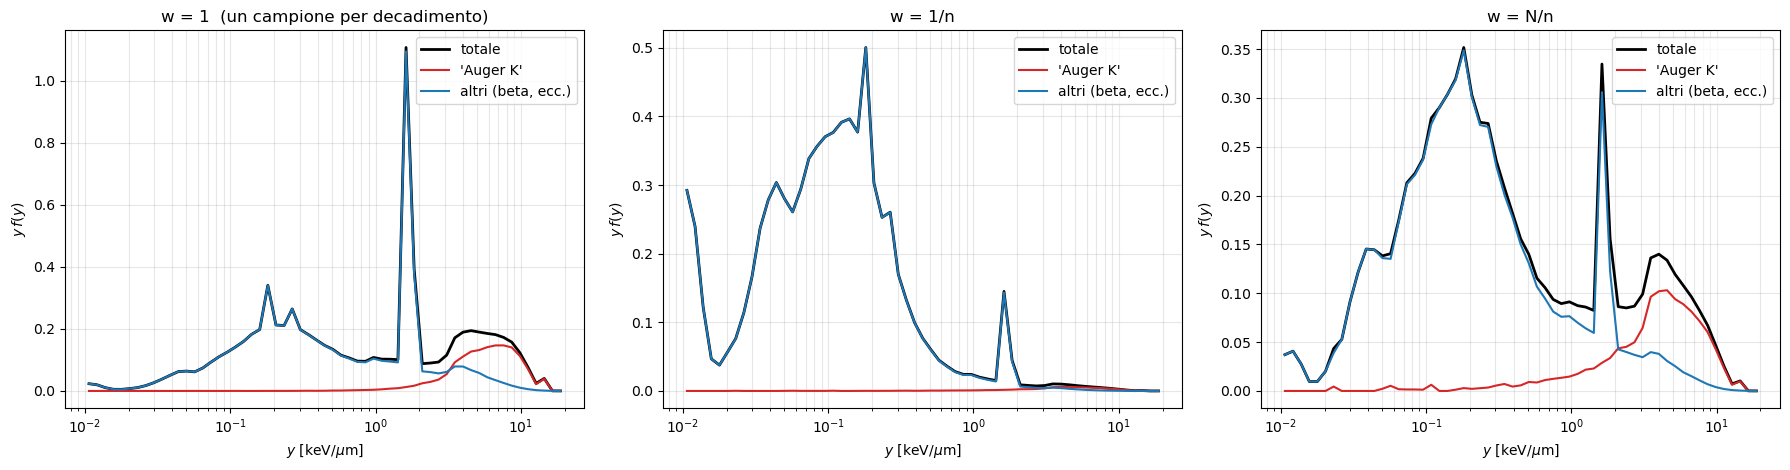

In [35]:
# --- classificazione per tipo di evento, dall'energia depositata nel nucleo ---
K_LO, K_HI = 8.0, 8.6     # keV: picco della cascata Auger da vacanza K del Ni (energia di legame 8.33 keV)
auger = ((full["E_nucl_keV"] > K_LO) & (full["E_nucl_keV"] < K_HI)).to_numpy()
y = full["y"].to_numpy()

W = {"w = 1  (un campione per decadimento)": np.ones(len(full)),
     "w = 1/n": full["w_1n"].to_numpy(),
     "w = N/n": full["w_Nn"].to_numpy()}

def yq(y, w):
    y_f = np.sum(w * y) / np.sum(w)
    y_d = np.sum(w * y**2) / np.sum(w * y)
    y_s = np.sum(w * y0**2 * (1 - np.exp(-(y / y0) ** 2))) / np.sum(w * y)
    return y_f, y_d, y_s

rows = []
for name, w in W.items():
    y_f, y_d, y_s = yq(y, w)
    al = alpha_0 + beta * K_CONV * y_s
    rows.append({"peso": name, "y_F": y_f, "y_D": y_d, "y*": y_s, "alpha": al, "RBE(D->0)": al / alpha_0,
                 "quota di Σw da 'Auger K'": w[auger].sum() / w.sum(),
                 "quota di Σw·y da 'Auger K'": (w * y)[auger].sum() / (w * y).sum()})
tab_tipi = pd.DataFrame(rows).set_index("peso")
display(tab_tipi.round(4))

print(f"eventi 'Auger K' (E_nucl in [{K_LO}, {K_HI}] keV): {100 * auger.mean():.1f}% dei decadimenti")
print(f"  con y > 10 keV/um (cascata quasi tutta nel dominio): {100 * (y[auger] > 10).mean():.1f}% di questi")
print(f"  mediana di n_scored/n_hits: {np.median(full['ratio'][auger]):.2f};  mediana di y: {np.median(y[auger]):.2f} keV/um")
print(f"altri eventi (beta, ecc.): mediana di y = {np.median(y[~auger]):.3f} keV/um;  "
      f"mediana di n_scored/n_hits = {np.median(full['ratio'][~auger]):.2f}")

# --- y f(y) totale e suddiviso per tipo di evento, per i tre pesi (normalizzato all'area del totale) ---
bins = np.logspace(-2, np.log10(20), 60)
xc = np.sqrt(bins[:-1] * bins[1:])
dln = np.diff(np.log(bins))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), sharey=False)
for a_, (name, w) in zip(ax, W.items()):
    tot = np.histogram(y, bins=bins, weights=w)[0]
    norm = tot.sum() * dln
    a_.semilogx(xc, tot / norm, "k", lw=2, label="totale")
    a_.semilogx(xc, np.histogram(y[auger], bins=bins, weights=w[auger])[0] / norm, color="tab:red", label="'Auger K'")
    a_.semilogx(xc, np.histogram(y[~auger], bins=bins, weights=w[~auger])[0] / norm, color="tab:blue", label="altri (beta, ecc.)")
    a_.set_title(name); a_.set_xlabel(r"$y$ [keV/$\mu$m]"); a_.set_ylabel(r"$y\,f(y)$")
    a_.grid(alpha=0.3, which="both"); a_.legend()
plt.tight_layout()
fig.savefig("f_y_per_tipo_evento.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Campionamento delle dosi (passo lento, una volta sola)
Ogni cellula virtuale accumula decadimenti uno dopo l'altro; la dose a N decadimenti è la somma cumulata delle dosi nucleari.
Una sola estrazione per cellula serve per tutti gli N.

In [36]:
def d_ref_at(s_target, g=None):
    """Dose di raggi X (alpha_0, beta*g) per avere S = s_target. Stesso G della radiazione studiata."""
    g = G if g is None else g
    b = beta * g
    return (-alpha_0 + np.sqrt(alpha_0**2 - 4 * b * np.log(s_target))) / (2 * b)

def sample_doses(dn, ns, rng):
    n_max = int(ns.max())
    idx = rng.integers(0, dn.size, size=(N_SIM, n_max), dtype=np.int32)
    cum = np.cumsum(dn[idx], axis=1)
    return cum[:, ns - 1].T                      # shape (len(ns), N_SIM)

dn_mean = np.mean([p["Nuclear_dose"].mean() for p in pools])
n_max = int(3 * d_ref_at(S_TARGET) / dn_mean)
ns = np.unique(np.linspace(1, n_max, N_POINTS).astype(int))
print(f"dose nucleare media per decadimento = {dn_mean:.3e} Gy ;  N da 1 a {n_max}")

t0 = time.time()
d_mats = []
for i, p in enumerate(pools):
    d_mats.append(sample_doses(p["Nuclear_dose"].to_numpy(), ns, rng))
    print(f"pool {i + 1}/{len(pools)}  ({time.time() - t0:.0f} s)")
d_mats = np.array(d_mats)                       # (pool, N, cellule)
np.savez("cache_dosi.npz", ns=ns, d_mats=d_mats)

dose nucleare media per decadimento = 1.541e-03 Gy ;  N da 1 a 14923
pool 1/10  (0 s)
pool 2/10  (1 s)
pool 3/10  (1 s)
pool 4/10  (2 s)
pool 5/10  (3 s)
pool 6/10  (3 s)
pool 7/10  (3 s)
pool 8/10  (3 s)
pool 9/10  (4 s)
pool 10/10  (4 s)


*Solo se riavvii il kernel:* non rifare il campionamento, ricarica la cache (e rilancia le celle 0-4).

In [37]:
# cache = np.load("cache_dosi.npz"); ns = cache["ns"]; d_mats = cache["d_mats"]

## 7. LQ + MKM: S(N), RBE(N), N10, D10 (veloce)

In [38]:
def lq(d_mat, alpha, g=None):
    g = G if g is None else g
    e = alpha * d_mat + beta * g * d_mat**2
    s = np.exp(-e)
    d_ref = (-alpha_0 + np.sqrt(alpha_0**2 + 4 * beta * g * e)) / (2 * beta * g)   # raggi X con lo stesso G
    rbe = np.where(d_mat > 0, d_ref / np.where(d_mat > 0, d_mat, 1.0), np.nan)
    return s, rbe

def crossing(ns, s_mean, d_mean, target=S_TARGET):
    if s_mean.min() > target:
        return np.nan, np.nan                    # S non arriva al target nella griglia
    s = np.maximum(np.minimum.accumulate(s_mean), 1e-300)
    ls = np.log(s)
    return (np.interp(np.log(target), ls[::-1], ns[::-1]),
            np.interp(np.log(target), ls[::-1], d_mean[::-1]))

def analyze(df, d_mat, mode, g=None):
    g = G if g is None else g
    y_f, y_d, y_star = micro(df, mode)
    alpha = alpha_0 + beta * K_CONV * y_star
    s, rbe = lq(d_mat, alpha, g)
    s_mean, d_mean = s.mean(axis=1), d_mat.mean(axis=1)
    n10, d10 = crossing(ns, s_mean, d_mean)
    return dict(S=s_mean, S_cell=s.std(axis=1),
                rbe=np.nanmean(rbe, axis=1), rbe_cell=np.nanstd(rbe, axis=1), D=d_mean,
                yF=y_f, yD=y_d, ystar=y_star, alpha=alpha,
                N10=n10, D10=d10, rbe10=d_ref_at(S_TARGET, g) / d10, rbe_max=alpha / alpha_0)

def aggregate(results):
    k = len(results)
    agg = {}
    for key in ("S", "rbe", "D"):
        arr = np.array([r[key] for r in results])
        agg[key] = arr.mean(axis=0)
        agg[key + "_sem"] = arr.std(axis=0, ddof=1) / np.sqrt(k)
    for key in ("S_cell", "rbe_cell"):
        agg[key] = np.mean([r[key] for r in results], axis=0)
    for key in ("yF", "yD", "ystar", "alpha", "N10", "D10", "rbe10", "rbe_max"):
        v = np.array([r[key] for r in results])
        agg[key] = v.mean()
        agg[key + "_sem"] = v.std(ddof=1) / np.sqrt(k)
    return agg

results = {m: [analyze(p, dm, m) for p, dm in zip(pools, d_mats)] for m in WEIGHT_MODES}
agg = {m: aggregate(results[m]) for m in WEIGHT_MODES}

tab = pd.DataFrame({
    m: {"y_F": a["yF"], "y_D": a["yD"], "y*": a["ystar"], "alpha": a["alpha"], "RBE(D->0)": a["rbe_max"],
        "N10": a["N10"], "N10 sem": a["N10_sem"], "D10 [Gy]": a["D10"], "D10 sem": a["D10_sem"],
        "RBE10": a["rbe10"], "RBE10 sem": a["rbe10_sem"]}
    for m, a in agg.items()}).T
print(f"Dose X di riferimento per S=10%: {d_ref_at(S_TARGET):.4f} Gy")
tab

Dose X di riferimento per S=10%: 7.6667 Gy


,y_F,y_D,y*,alpha,RBE(D->0),N10,N10 sem,D10 [Gy],D10 sem,RBE10,RBE10 sem
1/n,0.187951,1.888969,1.887031,0.157911,1.074226,4860.261226,17.376464,7.487576,0.000589,1.023927,0.000081
N/n,1.127767,4.804801,4.798184,0.174744,1.188735,4685.655638,16.781079,7.218475,0.000964,1.062099,0.000142


## 8. Grafico: sopravvivenza e RBE

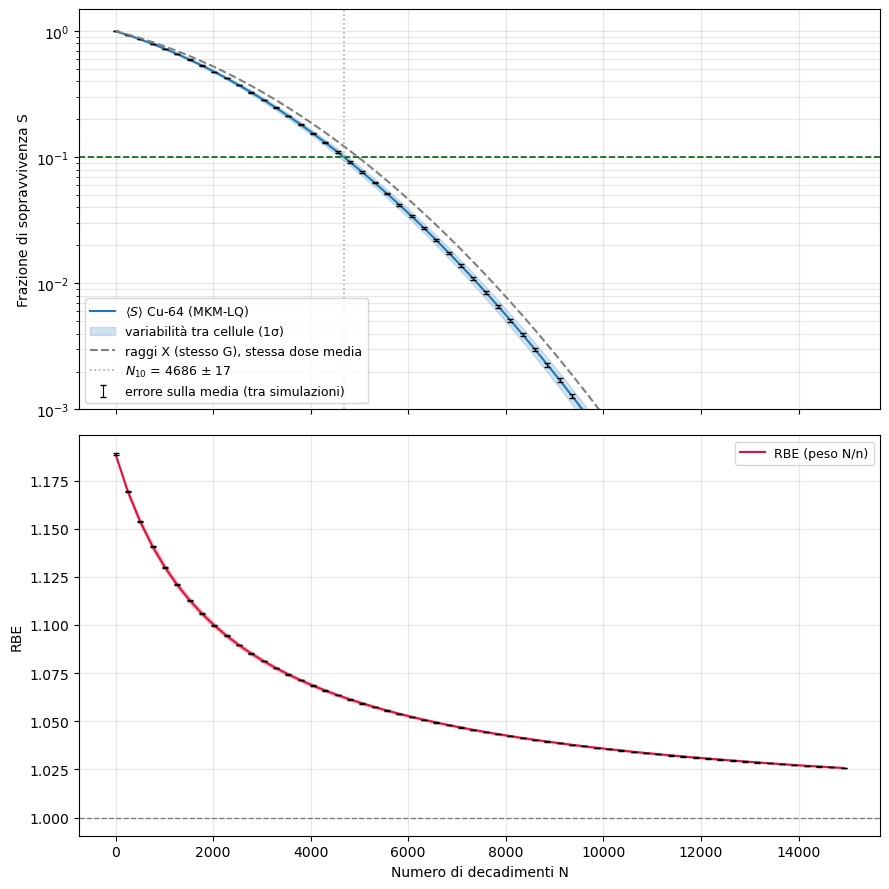

In [39]:
a = agg[PLOT_MODE]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 9), sharex=True)

ax1.plot(ns, a["S"], color="#1f77b4", label=r"$\langle S\rangle$ Cu-64 (MKM-LQ)")
ax1.fill_between(ns, np.clip(a["S"] - a["S_cell"], 1e-12, None), a["S"] + a["S_cell"],
                 color="#1f77b4", alpha=0.2, label="variabilità tra cellule (1σ)")
ax1.errorbar(ns, a["S"], yerr=a["S_sem"], fmt="none", ecolor="k", elinewidth=0.8, capsize=2,
             label="errore sulla media (tra simulazioni)")
ax1.plot(ns, np.exp(-alpha_0 * a["D"] - beta * G * a["D"] ** 2), "--", color="gray",
         label="raggi X (stesso G), stessa dose media")
ax1.axhline(S_TARGET, color="darkgreen", ls="--", lw=1.2)
ax1.axvline(a["N10"], color="darkgray", ls=":", lw=1.2, label=f"$N_{{10}}$ = {a['N10']:.0f} ± {a['N10_sem']:.0f}")
ax1.set_yscale("log"); ax1.set_ylim(1e-3, 1.5)
ax1.set_ylabel("Frazione di sopravvivenza S")
ax1.grid(True, which="both", alpha=0.3); ax1.legend(loc="lower left", fontsize=9)

ax2.plot(ns, a["rbe"], color="crimson", label=f"RBE (peso {PLOT_MODE})")
ax2.fill_between(ns, a["rbe"] - a["rbe_cell"], a["rbe"] + a["rbe_cell"], color="crimson", alpha=0.2)
ax2.errorbar(ns, a["rbe"], yerr=a["rbe_sem"], fmt="none", ecolor="k", elinewidth=0.8, capsize=2)
ax2.axhline(1.0, color="gray", ls="--", lw=1)
ax2.set_xlabel("Numero di decadimenti N"); ax2.set_ylabel("RBE")
ax2.grid(True, alpha=0.3); ax2.legend(loc="upper right", fontsize=9)

plt.tight_layout(); plt.savefig("cu64_S_RBE.png", dpi=200); plt.show()

## 9. (Opzionale) Effetto della riparazione: scansione di G
Dose protratta in ore (emivita del Cu-64 ≈ 12.7 h) → il termine quadratico si riduce (`G < 1`). L'RBE resta rispetto a raggi X con lo stesso `G`.
Usa la cache delle dosi, quindi è istantaneo. Con `G` piccolo S può non arrivare al 10% nella griglia di N: in quel caso compare `NaN`.

In [40]:
rows = []
for g in (1.0, 0.5, 0.2, 0.1, 0.05):
    res = [analyze(p, dm, PLOT_MODE, g=g) for p, dm in zip(pools, d_mats)]
    n10 = np.array([r["N10"] for r in res]); r10 = np.array([r["rbe10"] for r in res])
    rows.append(dict(G=g, N10=np.nanmean(n10), N10_sem=np.nanstd(n10, ddof=1) / np.sqrt(len(n10)),
                     RBE10=np.nanmean(r10)))
tab_G = pd.DataFrame(rows)
tab_G

,G,N10,N10_sem,RBE10
0,1.00,4685.655638,16.781079,1.062099
1,0.50,5696.366004,20.639944,1.083829
2,0.20,6885.276639,25.205632,1.116894
3,0.10,7551.157317,27.825695,1.140723
4,0.05,7993.553341,29.716112,1.159573


## 10. Riepilogo da copiare
Stampa in testo tutti i risultati delle celle precedenti, così puoi incollarli in una volta sola.

In [41]:
a = agg[PLOT_MODE]
allp = pd.concat(pools, ignore_index=True)
yy = allp["y"].to_numpy()

print("=" * 78)
print("RIEPILOGO ANALISI Cu-64")
print("=" * 78)
print(f"File: {len(FILES)} | eventi per file: {[len(d) for d in dfs]}")
print(f"Check allineamento (frazione righe coerenti): {[round(float(c), 4) for c in check_ok]}")
print(f"Seed: {seed_msg}")
print(f"Parametri: R_d={R_d} um, R_n={R_n} um, y0={y0}, alpha_0={alpha_0}, beta={beta}, G={G}, K_CONV={K_CONV:.4f}")
print(f"Statistica: N_SIM={N_SIM}, N_POINTS={N_POINTS}, pool={len(pools)}, N max={int(ns.max())}")
print(f"Dose nucleare media per decadimento = {dn_mean:.4e} Gy")
print(f"Dose X di riferimento per S=10%: {d_ref_at(S_TARGET):.4f} Gy")

print("\n--- Distribuzione di y (tutti i run) ---")
print(f"y: media={yy.mean():.4f}, mediana={np.median(yy):.4f}, max={yy.max():.3f} keV/um")
for mode in WEIGHT_MODES:
    w = weights(allp, mode)
    print(f"peso {mode:>3}: eventi con y>10 keV/um = {np.mean(yy > 10):.4f} (non pesato), "
          f"{w[yy > 10].sum() / w.sum():.4f} (pesato)")

print("\n--- Microdosimetria (media e sem tra pool) ---")
print(tab_micro.groupby("peso")[["yF", "yD", "ystar", "alpha"]].agg(["mean", "sem"]).round(5).to_string())

print("\n--- Risultati finali per schema di peso ---")
print(tab.round(5).to_string())

print(f"\n--- Curva S(N), RBE(N) (peso {PLOT_MODE}), 10 punti ---")
sel = np.linspace(0, len(ns) - 1, 10).astype(int)
curve = pd.DataFrame({
    "N": ns[sel], "D_media[Gy]": a["D"][sel],
    "S": a["S"][sel], "S_sem": a["S_sem"][sel], "S_cell": a["S_cell"][sel],
    "RBE": a["rbe"][sel], "RBE_sem": a["rbe_sem"][sel], "RBE_cell": a["rbe_cell"][sel]})
print(curve.round(5).to_string(index=False))

print(f"\n--- Scansione G (peso {PLOT_MODE}) ---")
try:
    print(tab_G.round(4).to_string(index=False))
except NameError:
    print("(cella 9 non eseguita)")

RIEPILOGO ANALISI Cu-64
File: 10 | eventi per file: [20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000, 20000]
Check allineamento (frazione righe coerenti): [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
Seed: run tutti diversi
Parametri: R_d=0.42 um, R_n=4.0 um, y0=150.0, alpha_0=0.147, beta=0.02, G=1.0, K_CONV=0.2891
Statistica: N_SIM=400, N_POINTS=60, pool=10, N max=14923
Dose nucleare media per decadimento = 1.5412e-03 Gy
Dose X di riferimento per S=10%: 7.6667 Gy

--- Distribuzione di y (tutti i run) ---
y: media=2.0412, mediana=0.9619, max=18.560 keV/um
peso 1/n: eventi con y>10 keV/um = 0.0234 (non pesato), 0.0003 (pesato)
peso N/n: eventi con y>10 keV/um = 0.0234 (non pesato), 0.0073 (pesato)

--- Microdosimetria (media e sem tra pool) ---
           yF                yD             ystar             alpha         
         mean      sem     mean      sem     mean      sem     mean      sem
peso                                                                    

## 11. Collegamento PET ↔ danno cellulare
La catena è: **coincidenze PET → decadimenti → dose nucleare → sopravvivenza**.
- `N_PET = eps_PET · BR_β⁺ · N_dec` (BR_β⁺ = positroni per decadimento, dalla sezione 5c/6.1; `eps_PET` è l'efficienza assoluta dello scanner, qui **illustrativa**);
- `D = N_dec · <D1>` (dose nucleare media per decadimento, `dn_mean`);
- `S = exp(-α D - β G D²)` (MKM + LQ).

La tabella dà, per diversi livelli di sopravvivenza, la dose, i decadimenti, le annichilazioni, le coincidenze PET per cellula e l'attività iniziale per cellula.
Il grafico riporta S(N) con un secondo asse in alto in coincidenze PET per cellula. Richiede le sezioni 5b-8 (`agg`, `dn_mean`, `ns`).

,D [Gy],N decadimenti,N_beta+ (annichilazioni),A0 [Bq/cellula] (senza washout),coincidenze/cellula (eps=1%),coincidenze/cellula (eps=5%),coincidenze/cellula (eps=10%)
S,,,,,,,
5.000000e-01,2.962,1922.116,337.139,0.029,3.371,16.857,33.714
1.000000e-01,7.216,4682.483,821.308,0.071,8.213,41.065,82.131
1.000000e-02,11.422,7411.285,1299.939,0.112,12.999,64.997,129.994
1.000000e-03,14.723,9552.886,1675.576,0.145,16.756,83.779,167.558
1.000000e-06,22.275,14453.105,2535.075,0.219,25.351,126.754,253.507
1.000000e-09,28.116,18243.344,3199.883,0.277,31.999,159.994,319.988


dose media per decadimento (nucleo) = 1.5412e-03 Gy
fattore di calibrazione kappa = <D1>/(eps*BR) = 0.8787 Gy per coincidenza per cellula  (eps = 1%)
fattore di calibrazione kappa = <D1>/(eps*BR) = 0.1757 Gy per coincidenza per cellula  (eps = 5%)
fattore di calibrazione kappa = <D1>/(eps*BR) = 0.0879 Gy per coincidenza per cellula  (eps = 10%)
Le coincidenze/cellula valgono se il PET vedesse TUTTI i decadimenti; per una finestra [t1,t2] si divide per (exp(-lam*t1) - exp(-lam*t2)).


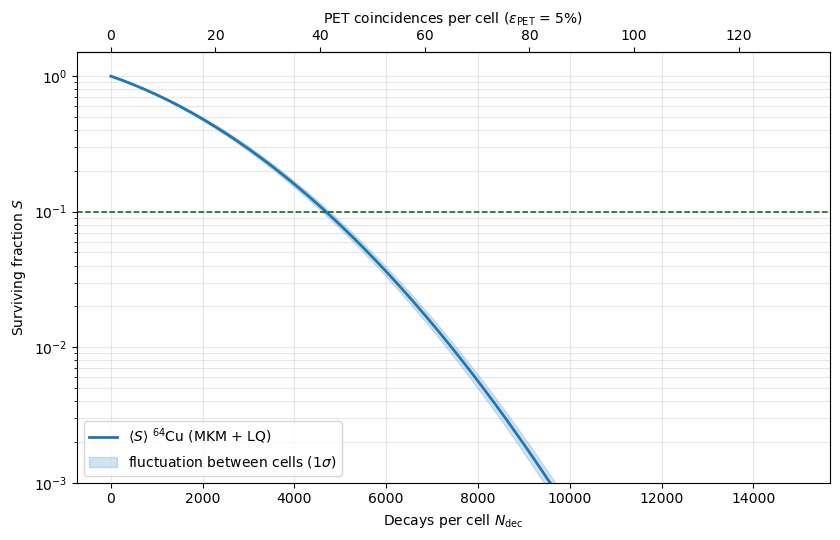

In [42]:
# ===== Collegamento PET <-> danno cellulare =====
BR_BETA_PLUS = 0.1754          # positroni per decadimento (sezione 6.1: 0.1754 +/- 0.0012)
EPS_PET = (0.01, 0.05, 0.10)   # efficienze ASSOLUTE di rivelazione: ILLUSTRATIVE, da sostituire con la sensibilita' dello scanner
EPS_FIG = 0.05                 # efficienza usata per l'asse superiore del grafico
lam = np.log(2) / (12.7 * 3600)                    # costante di decadimento [1/s]

a = agg[PLOT_MODE]
alpha_cu = a["alpha"]

def N_for_S(S_target, g=None):
    """Dose D e numero di decadimenti N per avere S = S_target (media): alpha*D + beta*g*D^2 = -ln S, D = N * dn_mean."""
    g = G if g is None else g
    E = -np.log(S_target)
    D = (-alpha_cu + np.sqrt(alpha_cu**2 + 4 * beta * g * E)) / (2 * beta * g)
    return D / dn_mean, D

rows = []
for S_t in (0.5, 0.1, 1e-2, 1e-3, 1e-6, 1e-9):
    N, D = N_for_S(S_t)
    r = {"S": S_t, "D [Gy]": D, "N decadimenti": N, "N_beta+ (annichilazioni)": N * BR_BETA_PLUS,
         "A0 [Bq/cellula] (senza washout)": N * lam}
    for e in EPS_PET:
        r[f"coincidenze/cellula (eps={e:.0%})"] = N * BR_BETA_PLUS * e
    rows.append(r)
tab_link = pd.DataFrame(rows).set_index("S")
display(tab_link.round(3))

print(f"dose media per decadimento (nucleo) = {dn_mean:.4e} Gy")
for e in EPS_PET:
    print(f"fattore di calibrazione kappa = <D1>/(eps*BR) = {dn_mean / (BR_BETA_PLUS * e):.4f} Gy per coincidenza per cellula  (eps = {e:.0%})")
print("Le coincidenze/cellula valgono se il PET vedesse TUTTI i decadimenti; per una finestra [t1,t2] si divide per (exp(-lam*t1) - exp(-lam*t2)).")

# --- grafico: S(N) con asse superiore in coincidenze PET per cellula ---
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.plot(ns, a["S"], color="#1f77b4", lw=2, label=r"$\langle S\rangle$ $^{64}$Cu (MKM + LQ)")
ax.fill_between(ns, np.clip(a["S"] - a["S_cell"], 1e-12, None), a["S"] + a["S_cell"],
                color="#1f77b4", alpha=0.2, label=r"fluctuation between cells ($1\sigma$)")
ax.axhline(S_TARGET, color="darkgreen", ls="--", lw=1.1)
ax.set_yscale("log"); ax.set_ylim(1e-3, 1.5)
ax.set_xlabel(r"Decays per cell $N_{\rm dec}$")
ax.set_ylabel(r"Surviving fraction $S$")
sec = ax.secondary_xaxis("top", functions=(lambda n: n * BR_BETA_PLUS * EPS_FIG,
                                           lambda c: c / (BR_BETA_PLUS * EPS_FIG)))
sec.set_xlabel(rf"PET coincidences per cell ($\varepsilon_{{\rm PET}}$ = {EPS_FIG:.0%})")
ax.grid(alpha=0.3, which="both"); ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig("S_vs_PET.png", dpi=200, bbox_inches="tight")
plt.show()

S = 0.1: N_dec = 4682, D = 7.22 Gy, coincidenze/cellula (eps=5%) = 41.1
S = 1e-09: N_dec = 18243, D = 28.12 Gy, coincidenze/cellula (eps=5%) = 160.0


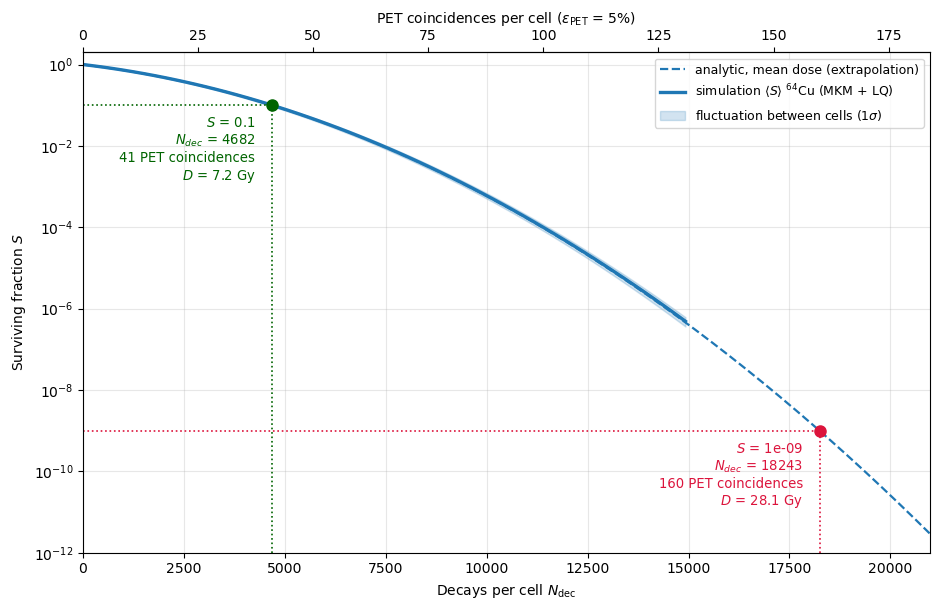

In [ ]:
# ===== Grafico PET <-> danno esteso fino a S = 1e-9 =====
a = agg[PLOT_MODE]
alpha_cu = a["alpha"]

N_end = 1.15 * N_for_S(1e-9)[0]
N_grid = np.linspace(0, N_end, 800)
D_grid = N_grid * dn_mean
S_ana = np.exp(-alpha_cu * D_grid - beta * G * D_grid**2)          # curva analitica sulla dose media

fig, ax = plt.subplots(figsize=(9.5, 6.2))
ax.plot(N_grid, S_ana, "--", color="#1f77b4", lw=1.6, label="analytic, mean dose (extrapolation)")
ax.plot(ns, a["S"], color="#1f77b4", lw=2.4, label=r"simulation $\langle S\rangle$ $^{64}$Cu (MKM + LQ)")
ax.fill_between(ns, np.clip(a["S"] - a["S_cell"], 1e-12, None), a["S"] + a["S_cell"],
                color="#1f77b4", alpha=0.2, label=r"fluctuation between cells ($1\sigma$)")

marks = ((0.1, "darkgreen"), (1e-9, "crimson"))
for S_t, col in marks:
    N_t, D_t = N_for_S(S_t)
    c_t = N_t * BR_BETA_PLUS * EPS_FIG
    ax.plot([N_t, N_t], [1e-12, S_t], ":", color=col, lw=1.2)
    ax.plot([0, N_t], [S_t, S_t], ":", color=col, lw=1.2)
    ax.plot(N_t, S_t, "o", color=col, ms=8, zorder=5)
    ax.annotate(f"$S$ = {S_t:g}\n$N_{{dec}}$ = {N_t:.0f}\n{c_t:.0f} PET coincidences\n$D$ = {D_t:.1f} Gy",
                xy=(N_t, S_t), xytext=(-12, -8), textcoords="offset points", ha="right", va="top",
                fontsize=9.5, color=col)
    print(f"S = {S_t:g}: N_dec = {N_t:.0f}, D = {D_t:.2f} Gy, coincidenze/cellula (eps={EPS_FIG:.0%}) = {c_t:.1f}")

ax.set_yscale("log"); ax.set_ylim(1e-12, 2); ax.set_xlim(0, N_end)
ax.set_xlabel(r"Decays per cell $N_{\rm dec}$")
ax.set_ylabel(r"Surviving fraction $S$")
sec = ax.secondary_xaxis("top", functions=(lambda n: n * BR_BETA_PLUS * EPS_FIG,
                                           lambda c: c / (BR_BETA_PLUS * EPS_FIG)))
sec.set_xlabel(rf"PET coincidences per cell ($\varepsilon_{{\rm PET}}$ = {EPS_FIG:.0%})")
ax.grid(alpha=0.3, which="both"); ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
fig.savefig("S_vs_PET_esteso.png", dpi=200, bbox_inches="tight")
plt.show()